# Mini-Project 2: Solar Micro-Grid Dispatch Planner

**Question.** A rural health centre in Kasese must meet two daily loads from solar (x) and battery (y):

- 3x + 2y = D1 (daytime load, kWh)
- 4x + y = D2 (critical-equipment load, kWh)

We build a `MicroGrid` class (with a `HybridMicroGrid` subclass), solve 30 days of demand, handle infeasible days,
price the energy and test how sensitive the answer is to noisy demand. Logic lives in `src/microgrid.py`.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))          # so that `from src.xxx import ...` works

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42                              # fixed seed -> Restart & Run All is reproducible
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

import timeit
from scipy import linalg
from src.microgrid import (MicroGrid, HybridMicroGrid, SingularSystemError, generate_demand_csv,
                           load_demand_csv, interactive_day, prompt_demand, parse_demand)
DATA_DIR = ROOT / "data"

## Task 1 - `MicroGrid` and a well-posedness check

In [2]:
grid = MicroGrid()
print(grid)
print("A =\n", grid.A)
print("determinant      :", round(grid.determinant(), 6))
print("condition number :", round(grid.condition_number(), 4))
print("well posed?      :", grid.is_well_posed())

# Closed-form solution by hand (eliminate y):  x = (2*D2 - D1)/5 ,  y = (4*D1 - 3*D2)/5
d1, d2 = 40, 45
print("hand:", ((2*d2 - d1)/5, (4*d1 - 3*d2)/5), " code:", grid.solve_day(d1, d2))

# What a singular system looks like
try:
    MicroGrid([[1, 2], [2, 4]]).solve_day(1, 2)
except SingularSystemError as err:
    print("Singular example ->", err)

MicroGrid(A=[[3.0, 2.0], [4.0, 1.0]])
A =
 [[3. 2.]
 [4. 1.]]
determinant      : -5.0
condition number : 5.8284
well posed?      : True
hand: (10.0, 5.0)  code: [10.  5.]
Singular example -> system is singular or ill-conditioned (det=0, cond=4.8e+16)


**Determinant = -5 (non-zero).** The two lines 3x+2y = D1 and 4x+y = D2 are not parallel, so there is exactly one
(x, y) for every (D1, D2). The sign only records orientation, and the size tells us the map is not collapsing area to zero.
**Condition number = 5.83.** It bounds how much a relative error in the demands can be magnified in the answer:
||dx||/||x|| <= cond x ||dD||/||D||. A value near 1 is ideal and values around 10^k lose about k digits, so 5.8 is very
comfortable. A determinant near 0 with a huge condition number (as in the singular example) would mean tiny meter errors
produce wild dispatch plans.

**Feasibility region.** From the closed form, x >= 0 needs D1/D2 <= 2 and y >= 0 needs D1/D2 >= 0.75. Outside
that band no non-negative dispatch satisfies both equations, which matters in Task 4.

## Task 2 - Two input modes

**(a) Interactive `input()` with validation.** A notebook run must not block, so we show the validator with scripted answers (the empty, text and negative entries are rejected and re-prompted). In a terminal you would simply call `interactive_day(MicroGrid())`.

In [3]:
scripted = iter(["", "abc", "-4", "40", "  ", "45"])       # what a careless user might type
def fake_input(prompt):
    answer = next(scripted)
    print(f"{prompt}{answer!r}")
    return answer

x, y = interactive_day(grid, input_fn=fake_input)      # real use: interactive_day(grid)  (uses input())
print("\nDispatch: solar = %.2f kWh, battery = %.2f kWh" % (x, y))

for bad in ["", "abc", "-1", "nan", "inf"]:
    try: parse_demand(bad)
    except ValueError as e: print(f"parse_demand({bad!r:6}) -> {e}")

Enter daytime demand D1 (kWh): ''
  Invalid input: value is empty. Please try again.
Enter daytime demand D1 (kWh): 'abc'
  Invalid input: 'abc' is not a number. Please try again.
Enter daytime demand D1 (kWh): '-4'
  Invalid input: value must not be negative. Please try again.
Enter daytime demand D1 (kWh): '40'
Enter critical demand D2 (kWh): '  '
  Invalid input: value is empty. Please try again.
Enter critical demand D2 (kWh): '45'

Dispatch: solar = 10.00 kWh, battery = 5.00 kWh
parse_demand(''    ) -> value is empty
parse_demand('abc' ) -> 'abc' is not a number
parse_demand('-1'  ) -> value must not be negative
parse_demand('nan' ) -> value must be finite
parse_demand('inf' ) -> value must be finite


**(b) Load 30 days from CSV.** We generate the file with a seeded generator: a weekly pattern (busy weekdays, quiet weekends for the daytime load, while the critical equipment load stays steady) plus Gaussian noise.

In [4]:
csv_path = generate_demand_csv(DATA_DIR / "demand_30days.csv", days=30, seed=SEED)
demand = load_demand_csv(csv_path)                      # shape (2, 30)
demand_df = pd.DataFrame(demand.T, columns=["D1 (kWh)", "D2 (kWh)"], index=pd.RangeIndex(1, 31, name="day"))
print(csv_path.name, "->", demand.shape)
display(demand_df.describe().round(2))

demand_30days.csv -> (2, 30)


,D1 (kWh),D2 (kWh)
count,30.000,30.000
mean,39.150,45.350
std,5.110,3.170
min,29.540,39.530
25%,34.380,43.120
50%,40.830,44.920
75%,43.130,47.740
max,46.260,53.790


## Task 3 - 30 days: Python loop vs one vectorised `scipy.linalg.solve`

In [5]:
sol_loop = grid.solve_loop(demand)            # 30 separate solves
sol_vec  = grid.solve_vectorised(demand)      # a single solve with a 2x30 right-hand side
print("Same answer?", np.allclose(sol_loop, sol_vec))

N = 300
t_loop = timeit.timeit(lambda: grid.solve_loop(demand), number=N) / N
t_vec  = timeit.timeit(lambda: grid.solve_vectorised(demand), number=N) / N
print(f"loop       : {t_loop*1e6:9.1f} microseconds per 30 days")
print(f"vectorised : {t_vec*1e6:9.1f} microseconds per 30 days")
print(f"speed-up   : {t_loop/t_vec:5.1f}x")

Same answer? True


loop       :    2111.5 microseconds per 30 days
vectorised :      66.3 microseconds per 30 days
speed-up   :  31.9x


The vectorised call is dozens of times faster. The loop pays Python overhead (function call, input validation and a
well-posedness check with `det` and `cond`, and a fresh LU factorisation) 30 times. `linalg.solve(A, B)` factorises A **once** and
back-substitutes all 30 right-hand sides in compiled code. For 2x2 systems the arithmetic is trivial, so almost all of the
saving is overhead removal, which is why the gap is so large.

## Task 4 - Infeasible days (negative solar or battery)

In [6]:
res = grid.dispatch(demand, strategy="nnls")
bad_days = np.where(res.infeasible)[0]
print("Infeasible days (1-based):", (bad_days + 1).tolist(), f"-> {len(bad_days)} of 30")
print("negative solar days:", int((res.raw[0] < -1e-9).sum()), "| negative battery days:", int((res.raw[1] < -1e-9).sum()))
weekday = np.array(["Mon","Tue","Wed","Thu","Fri","Sat","Sun"])[bad_days % 7]

clip = grid.dispatch(demand, "clip")
report = pd.DataFrame({
    "weekday": weekday,
    "D1": demand[0, bad_days], "D2": demand[1, bad_days],
    "raw solar": res.raw[0, bad_days], "raw battery": res.raw[1, bad_days],
    "NNLS solar": res.final[0, bad_days], "NNLS battery": res.final[1, bad_days],
    "unmet D1 (NNLS)": grid.unmet_demand(res.final, demand)[0, bad_days],
    "unmet D2 (NNLS)": grid.unmet_demand(res.final, demand)[1, bad_days],
    "unmet D2 (clip)": grid.unmet_demand(clip.final, demand)[1, bad_days],
}, index=pd.Index(bad_days + 1, name="day"))
display(report.round(2))
print("Worst unmet load  clip: %.2f kWh | NNLS: %.2f kWh" % (np.abs(grid.unmet_demand(clip.final, demand)).max(),
                                                          np.abs(grid.unmet_demand(res.final, demand)).max()))

Infeasible days (1-based): [5, 6, 7, 14, 20, 21, 28] -> 7 of 30
negative solar days: 0 | negative battery days: 7


,weekday,D1,D2,raw solar,raw battery,NNLS solar,NNLS battery,unmet D1 (NNLS),unmet D2 (NNLS),unmet D2 (clip)
day,,,,,,,,,,
5,Fri,35.120,47.460,11.960,-0.380,11.810,0.000,-0.300,0.230,-0.380
6,Sat,29.540,48.710,13.580,-5.590,11.340,0.000,-4.480,3.360,-5.590
7,Sun,30.320,43.420,11.300,-1.800,10.590,0.000,-1.440,1.080,-1.800
14,Sun,32.820,44.800,11.360,-0.620,11.110,0.000,-0.500,0.370,-0.620
20,Sat,32.680,44.460,11.250,-0.530,11.040,0.000,-0.430,0.320,-0.530
21,Sun,29.540,45.030,12.100,-3.390,10.750,0.000,-2.710,2.030,-3.390
28,Sun,30.910,49.850,13.760,-5.180,11.690,0.000,-4.150,3.110,-5.180


Worst unmet load  clip: 11.19 kWh | NNLS: 4.48 kWh


**Strategy chosen: non-negative least squares (`scipy.optimize.nnls`) + an explicit report.** Every infeasible day
is one where D1 is low relative to D2 (a quiet weekend day with the critical load unchanged), so the exact solution wants y < 0.
Physically a negative battery draw means the battery would be *charging*, which this model does not allow. Simple clipping
(set y = 0, keep x) leaves the largest unmet load, while NNLS finds the non-negative (x, y) with the smallest total
residual, and the report shows how much load is left unmet. In real operation that shortfall would be met by the grid, diesel
or shedding non-critical load, which is exactly what the hybrid extension explores. Feasible days are left untouched.

## Task 5 - Volatility of solar vs battery (statistics module)

In [7]:
solar, battery = res.final[0], res.final[1]
vol = pd.DataFrame({"solar (kWh/day)": MicroGrid.describe(solar), "battery (kWh/day)": MicroGrid.describe(battery)})
display(vol.round(3))
print("More volatile source:", "battery" if vol.loc["cv", "battery (kWh/day)"] > vol.loc["cv", "solar (kWh/day)"] else "solar")

,solar (kWh/day),battery (kWh/day)
mean,10.078,4.691
variance,1.893,13.389
stdev,1.376,3.659
cv,0.137,0.780


More volatile source: battery


The battery is more volatile on **both** measures: absolute (variance about 13.4 vs 1.9 kWh^2) and relative (CV about 0.78 vs
0.14). Because y = (4 D1 - 3 D2)/5 is a *difference* of two noisy loads of similar size, noise is amplified and even flips the sign, while
solar x = (2 D2 - D1)/5 is dominated by a steady D2. CV, not raw variance, is the fair comparison since the two sources have
different means.

## Task 6 - Cost model (solar UGX 150/kWh, battery UGX 450/kWh)

In [8]:
cost = MicroGrid.daily_cost(solar, battery)                # UGX per day
print(f"Mean daily cost : UGX {cost.mean():,.0f}")
print(f"Monthly (30 d)  : UGX {cost.sum():,.0f}")
print(f"  of which solar UGX {(solar*150).sum():,.0f} | battery UGX {(battery*450).sum():,.0f}")
share = (battery*450).sum() / cost.sum()
print(f"Battery is {battery.sum()/(solar.sum()+battery.sum()):.0%} of energy but {share:.0%} of cost")
print(f"(Monthly cost if we ignored the infeasibility problem and used the raw solution: "
      f"UGX {MicroGrid.daily_cost(res.raw[0], res.raw[1]).sum():,.0f} - lower only because negative battery use earns 'credit'.)")

Mean daily cost : UGX 3,622
Monthly (30 d)  : UGX 108,674
  of which solar UGX 45,352 | battery UGX 63,322
Battery is 32% of energy but 58% of cost
(Monthly cost if we ignored the infeasibility problem and used the raw solution: UGX 101,851 - lower only because negative battery use earns 'credit'.)


## Task 7 - Stacked bars with a cost axis

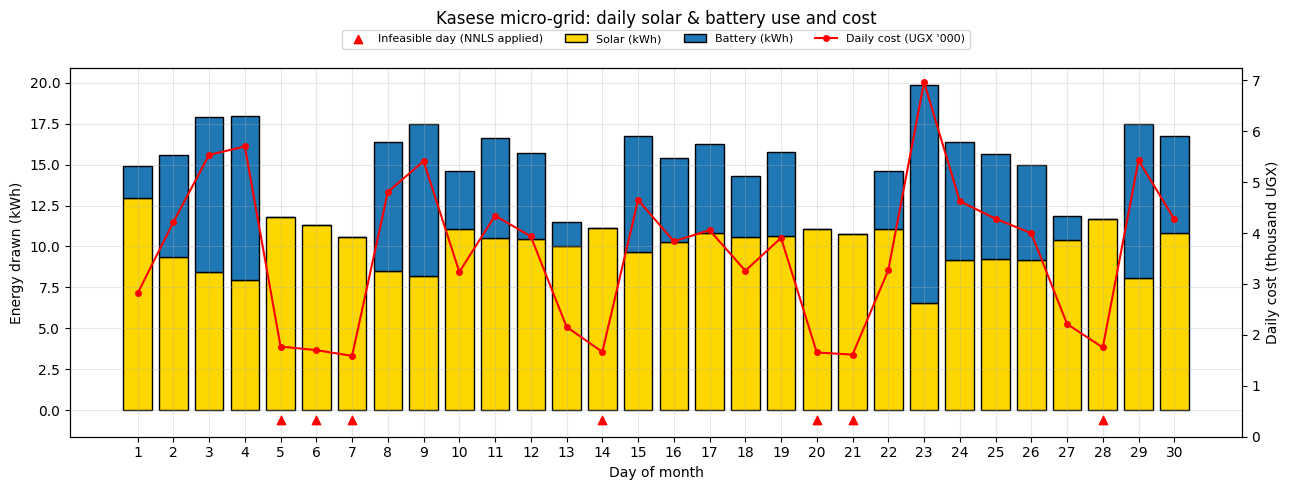

In [9]:
days = np.arange(1, 31)
fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(days, solar, color="gold", edgecolor="k", label="Solar (kWh)")
ax.bar(days, battery, bottom=solar, color="tab:blue", edgecolor="k", label="Battery (kWh)")
ax.scatter(days[res.infeasible], np.full(res.infeasible.sum(), -0.6), marker="^", color="red", zorder=5,
           label="Infeasible day (NNLS applied)")
ax.set_xlabel("Day of month"); ax.set_ylabel("Energy drawn (kWh)"); ax.set_xticks(days)
ax2 = ax.twinx(); ax2.grid(False)
ax2.plot(days, cost / 1000, "r-o", ms=4, label="Daily cost (UGX '000)"); ax2.set_ylabel("Daily cost (thousand UGX)"); ax2.set_ylim(0, None)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper center", ncol=4, fontsize=8, bbox_to_anchor=(0.5, 1.12))
ax.set_title("Kasese micro-grid: daily solar & battery use and cost", pad=32); plt.tight_layout(); plt.show()

## Extension A - `HybridMicroGrid` (solar + battery + diesel, 3x3)

Diesel z enters the daytime load, not the critical circuit, plus a balance equation:

- 3x + 2y + z = D1
- 4x + y = D2
- x + y + z = D3

In [10]:
hyb = HybridMicroGrid()
print("A =\n", hyb.A, "\ndet =", round(hyb.determinant(), 3), "| cond =", round(hyb.condition_number(), 2), "| rank =", hyb.rank())
u = hyb.solve_day(40, 45, 16)
print("x, y, z =", np.round(u, 3), "| check A@u =", np.round(hyb.A @ u, 6))

# Linearly dependent 3rd equation: row3 = row1 + row2  ->  7x + 3y + z = D1 + D2
dep = HybridMicroGrid([[3, 2, 1], [4, 1, 0], [7, 3, 1]])
print("\nDependent system: det = %.2e | cond = %.2e | rank = %d" % (dep.determinant(), dep.condition_number(), dep.rank()))
try:
    dep.solve_day(40, 45, 85)
except SingularSystemError as err:
    print("solve_day ->", err)
print("consistent RHS (D3 = D1+D2 = 85):", dep.solve_day_safe(40, 45, 85))
print("inconsistent RHS (D3 = 60)      :", dep.solve_day_safe(40, 45, 60))

A =
 [[3. 2. 1.]
 [4. 1. 0.]
 [1. 1. 1.]] 
det = -2.0 | cond = 23.89 | rank = 3
x, y, z = [10.5  3.   2.5] | check A@u = [40. 45. 16.]

Dependent system: det = -9.52e-16 | cond = 5.05e+16 | rank = 2
solve_day -> system is singular or ill-conditioned (det=-9.52e-16, cond=5.05e+16)
consistent RHS (D3 = D1+D2 = 85): (array([10.23809524,  4.04761905,  1.19047619]), 'least-squares (rank 2 < 3: infinitely many or no solutions)')
inconsistent RHS (D3 = 60)      : (array([8.45238095, 2.85714286, 0.5952381 ]), 'least-squares (rank 2 < 3: infinitely many or no solutions)')


**Linearly dependent equation.** If the new equation is a combination of the others (row 3 = row 1 + row 2) the determinant is 0, the condition
number explodes (~10^16 is just floating-point noise), and the rank drops to 2. Then either **no solution** exists (if D3 disagrees with D1 + D2)
or **infinitely many** exist (if D3 = D1 + D2): a whole line of (x, y, z) fits, so the planner cannot choose a unique dispatch. `solve_day` therefore
raises `SingularSystemError`, and `solve_day_safe` falls back to the minimum-norm least-squares solution and says so. The remedy is
to add an *independent* piece of information (a cost objective, or a capacity limit) rather than a redundant equation.

## Extension B - Sensitivity: +-5 % demand noise (Monte Carlo, 1,000 draws)

,base,mean,std,min,max,max % change
solar x,10.000,10.018,0.570,8.783,11.243,12.426
battery y,5.000,4.968,1.216,2.166,7.798,56.681


Largest observed amplification of relative error : 5.81
Theoretical upper bound (condition number)       : 5.83


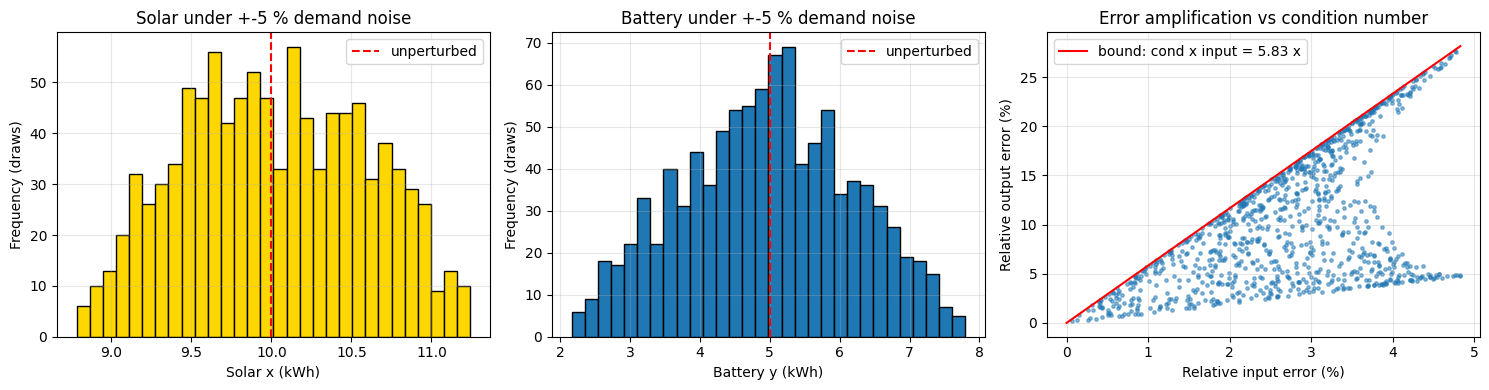

In [11]:
sens = grid.sensitivity([40, 45], pct=0.05, n_draws=1000, seed=SEED)
base, sols = sens["base"], sens["solutions"]
summary = pd.DataFrame({
    "base": base, "mean": sols.mean(axis=1), "std": sols.std(axis=1, ddof=1),
    "min": sols.min(axis=1), "max": sols.max(axis=1),
    "max % change": np.maximum(np.abs(sols.min(axis=1)-base), np.abs(sols.max(axis=1)-base)) / base * 100,
}, index=["solar x", "battery y"])
display(summary.round(3))
print(f"Largest observed amplification of relative error : {sens['max_amplification']:.2f}")
print(f"Theoretical upper bound (condition number)       : {sens['cond']:.2f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, i, lab, c in zip(axes[:2], [0, 1], ["Solar x (kWh)", "Battery y (kWh)"], ["gold", "tab:blue"]):
    ax.hist(sols[i], bins=30, color=c, edgecolor="k"); ax.axvline(base[i], color="r", ls="--", label="unperturbed")
    ax.set_xlabel(lab); ax.set_ylabel("Frequency (draws)"); ax.set_title(f"{lab.split(' ')[0]} under +-5 % demand noise"); ax.legend()
axes[2].scatter(sens["rel_in"] * 100, sens["rel_out"] * 100, s=6, alpha=0.5)
lim = sens["rel_in"].max() * 100
axes[2].plot([0, lim], [0, lim * sens["cond"]], "r-", label=f"bound: cond x input = {sens['cond']:.2f} x")
axes[2].set_xlabel("Relative input error (%)"); axes[2].set_ylabel("Relative output error (%)")
axes[2].set_title("Error amplification vs condition number"); axes[2].legend()
plt.tight_layout(); plt.show()

All 1,000 points sit under the red line: no draw amplifies error by more than cond(A) = 5.83, and the worst draw (5.81) almost touches
it, so the bound is nearly tight. Note the component view: a +-5 % change in demand moves solar by about +-12 % but battery by about +-56 %, because y
is the small difference 4 D1 - 3 D2 of two large numbers (cancellation). The *norm-wise* condition number is modest, but the *relative* sensitivity of the smallest
component is much larger. Battery planning needs margin, or better metering.

## Findings & Limitations

## Findings & Limitations

**Findings.** The system is well posed (determinant -5, condition number 5.83), so each day has a unique solution and a
5 % metering error can inflate the relative error of the answer by at most about 5.8 times. Solving 30 days in one
vectorised call was roughly 30 to 50 times faster than a loop (tens of microseconds against about 2 milliseconds; exact timings vary from run to run). Seven of the 30 days (six weekend days and one Friday) were physically infeasible, always because the exact solution required a *negative battery* draw when the daytime load fell but the critical
load did not. Non-negative least squares removed the negatives and left at most 4.5 kWh of load unmet, against 11.2 kWh
after clipping. The battery is the more volatile source (CV 0.78 against 0.14 for solar), and the monthly energy cost is about UGX 109,000,
with the battery providing roughly a third of the energy but well over half of the cost. Sensitivity work showed the
battery component moves four to five times more than solar, in relative terms, under the same demand noise.

**Limitations.** Demand data are synthetic. The model is static: it ignores battery state of charge, charging from surplus solar, night-time load,
weather and the fact that solar output is set by the sun, not by us. NNLS "solves" infeasibility mathematically but the shortfall
is real and needs a physical source (grid, diesel or load shedding). Prices are illustrative and constant, and the diesel equations in the hybrid
extension are invented for illustration, not measured. Noise in D1 and D2 was assumed independent and uniform, whereas
real loads are correlated.